# Stage 3 — Model Development & Experiment Tracking [30 Marks]

This notebook trains, evaluates, tracks and registers the 30-day readmission models. The Stage 2 preparation is reused from `data_prep.py`, so the cleaning rules are identical to `notebooks/Data_Preparation.ipynb`:

- `?` → NaN, `weight` and constant columns dropped, first encounter per patient, expired/hospice discharges removed, binary target `readmitted_30d` (`<30` = 1).
- Row-wise engineered features: ICD-9 diagnosis groups, age midpoint, service utilisation, medication-change count; medical specialty is grouped to its top 10 categories inside the pipeline.
- A stratified 70/15/15 train/validation/test split (`random_state=42`) is created **before** any fitting. All imputation, scaling and encoding is inside each model `Pipeline`, so it is fitted on the training split only.

Models are compared on the **validation** split. The test split is used once, for the selected model only.

In [1]:
import os
import sys
import logging
import random
import warnings
from pathlib import Path
from time import perf_counter

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
import skops.io as sio
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.WARNING)
logging.getLogger("alembic").setLevel(logging.WARNING)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = Path(".").resolve().parent if Path(".").resolve().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(PROJECT_ROOT))
import data_prep as dp

RANDOM_STATE = dp.RANDOM_STATE
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

# Decision threshold for recall/precision/F1/confusion matrices (representative default).
THRESHOLD = 0.50

# Local MLflow store: SQLite backend for runs + registry, artifacts in a local folder.
# (MLflow 3.x places the plain ./mlruns file store in maintenance mode and recommends a database backend.)
MLFLOW_TRACKING_URI = f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}"
MLFLOW_ARTIFACT_ROOT = (PROJECT_ROOT / "mlartifacts").as_uri()
EXPERIMENT_NAME = "hospital-readmission-30d"
REGISTERED_MODEL_NAME = "hospital-readmission-30d-classifier"
PRODUCTION_ALIAS = "production"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=MLFLOW_ARTIFACT_ROOT)
experiment = mlflow.set_experiment(EXPERIMENT_NAME)

print(f"Random seed: {RANDOM_STATE}")
print(f"MLflow tracking URI: {MLFLOW_TRACKING_URI}")
print(f"MLflow experiment: {EXPERIMENT_NAME} (id {experiment.experiment_id})")

Random seed: 42
MLflow tracking URI: sqlite:///C:/Users/aruna/OneDrive/Documents/upgrad/Capstone-Implementation-Package-MLOps/mlflow.db
MLflow experiment: hospital-readmission-30d (id 1)


In [2]:
# Reproduce the Stage 2 preparation and the fixed train/validation/test partitions.
data = dp.prepare_splits()
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]
NUMERIC, CATEGORICAL, SPECIALTY = data["numeric"], data["categorical"], data["specialty"]

split_summary = pd.DataFrame(
    {
        "rows": [len(y_train), len(y_val), len(y_test)],
        "positives": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
        "positive_rate_percent": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)],
    },
    index=pd.Index(["train", "validation", "test"], name="split"),
)
display(split_summary)
print(f"Total rows: {split_summary['rows'].sum():,}")
print(f"Model inputs: {X_train.shape[1]} columns "
      f"({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical, {len(SPECIALTY)} specialty)")
print("Identifiers and target excluded from inputs:",
      not set(dp.ID_COLUMNS + [dp.TARGET]) & set(X_train.columns))

,rows,positives,positive_rate_percent
split,,,
train,48981,4394,8.97
validation,10496,942,8.97
test,10496,941,8.97


Total rows: 69,973
Model inputs: 46 columns (11 numeric, 34 categorical, 1 specialty)
Identifiers and target excluded from inputs: True


## Task 3.1 — Baseline Model [5 Marks]

### 3.1.1 — Logistic Regression baseline trained (Pipeline, imbalance handled) [3]

The baseline is an interpretable Logistic Regression inside one `Pipeline`: the Stage 2 `ColumnTransformer` (median-impute + scale numerics; impute + one-hot encode categoricals with `handle_unknown="ignore"`) followed by the classifier. Because the whole pipeline is fitted on the training split, no validation or test information enters preprocessing.

Imbalance is handled with `class_weight="balanced"`: each class is weighted inversely to its frequency, so the ~9% positive class carries about as much total weight as the negative class. No rows are resampled.

In [3]:
# 3.1.1 — Logistic Regression baseline trained (Pipeline, imbalance handled)
LR_PARAMS = {
    "C": 1.0,
    "class_weight": "balanced",
    "solver": "lbfgs",
    "max_iter": 2000,
    "random_state": RANDOM_STATE,
}

baseline_pipeline = Pipeline(
    [
        ("preprocess", dp.build_preprocessor(NUMERIC, CATEGORICAL, SPECIALTY)),
        ("model", LogisticRegression(**LR_PARAMS)),
    ]
)

start = perf_counter()
baseline_pipeline.fit(X_train, y_train)
baseline_train_seconds = perf_counter() - start

n_features_out = len(baseline_pipeline.named_steps["preprocess"].get_feature_names_out())
print(f"Trained on {len(X_train):,} training rows in {baseline_train_seconds:.1f}s")
print(f"Features after preprocessing: {n_features_out}")
print("Converged:", baseline_pipeline.named_steps["model"].n_iter_[0] < LR_PARAMS["max_iter"])
baseline_pipeline

Trained on 48,981 training rows in 2.2s
Features after preprocessing: 201
Converged: True


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['race','gender','admission_type_id',...,'age_midpoint', 'service_utilisation','num_med_changes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

### 3.1.2 — Baseline evaluated on validation [2]

The baseline is scored on the validation split, which was not used for fitting. ROC-AUC and PR-AUC use the predicted probabilities and do not depend on a threshold. Recall, precision, F1 and accuracy use the 0.50 decision threshold.

In [4]:
# 3.1.2 — Baseline evaluated on validation
def evaluate(model, X, y, threshold=THRESHOLD):
    """Imbalance-aware metrics for a fitted classifier on one split."""
    scores = model.predict_proba(X)[:, 1]
    predictions = (scores >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y, scores),
        "pr_auc": average_precision_score(y, scores),
        "recall": recall_score(y, predictions, zero_division=0),
        "precision": precision_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
        "accuracy": accuracy_score(y, predictions),
    }


baseline_val_metrics = evaluate(baseline_pipeline, X_val, y_val)
display(pd.Series(baseline_val_metrics, name="Logistic Regression (validation)").round(4).to_frame())

baseline_val_pred = (baseline_pipeline.predict_proba(X_val)[:, 1] >= THRESHOLD).astype(int)
print(classification_report(y_val, baseline_val_pred, target_names=["not readmitted <30d", "readmitted <30d"], digits=3))

,Logistic Regression (validation)
roc_auc,0.6525
pr_auc,0.1723
recall,0.5308
precision,0.1387
f1,0.2199
accuracy,0.6621


                     precision    recall  f1-score   support

not readmitted <30d      0.936     0.675     0.784      9554
    readmitted <30d      0.139     0.531     0.220       942

           accuracy                          0.662     10496
          macro avg      0.537     0.603     0.502     10496
       weighted avg      0.864     0.662     0.734     10496



## Task 3.2 — Advanced Model [8 Marks]

### 3.2.1 — XGBoost trained (Pipeline, `scale_pos_weight` imbalance handled) [5]

XGBoost uses the same preprocessing in its own `Pipeline`, so both models see identical inputs and partitions. Gradient-boosted trees can capture non-linear effects and interactions, such as prior inpatient visits combined with discharge disposition, that a linear model cannot.

Imbalance is handled with `scale_pos_weight = negatives / positives`, calculated from the **training split only**. This scales up the loss on positive cases by about 10×. The hyperparameters are conservative (shallow trees, a small learning rate, row/column subsampling). They were chosen beforehand from five small configurations using 5-fold cross-validated ROC-AUC on the **training split only**. The best scored ≈ 0.652, against ≈ 0.648 for the first setting tried. Validation data is not used for tuning, so the validation comparison stays fair.

In [5]:
# 3.2.1 — XGBoost trained (Pipeline, scale_pos_weight imbalance handled)
negatives, positives = int((y_train == 0).sum()), int((y_train == 1).sum())
scale_pos_weight = negatives / positives
print(f"Training split: {negatives:,} negatives / {positives:,} positives -> scale_pos_weight = {scale_pos_weight:.3f}")

XGB_PARAMS = {
    "n_estimators": 600,
    "learning_rate": 0.02,
    "max_depth": 4,
    "min_child_weight": 10,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "scale_pos_weight": round(scale_pos_weight, 4),
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

xgb_pipeline = Pipeline(
    [
        ("preprocess", dp.build_preprocessor(NUMERIC, CATEGORICAL, SPECIALTY)),
        ("model", XGBClassifier(**XGB_PARAMS)),
    ]
)

start = perf_counter()
xgb_pipeline.fit(X_train, y_train)
xgb_train_seconds = perf_counter() - start
print(f"Trained on {len(X_train):,} training rows in {xgb_train_seconds:.1f}s")
xgb_pipeline

Training split: 44,587 negatives / 4,394 positives -> scale_pos_weight = 10.147


Trained on 48,981 training rows in 3.9s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['race','gender','admission_type_id',...,'age_midpoint', 'service_utilisation','num_med_changes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

### 3.2.2 — Advanced model evaluated on validation [3]

The XGBoost pipeline is scored on the same validation split, with the same metrics and the same 0.50 threshold as the baseline. The top feature importances show which inputs the trees rely on most.

,XGBoost (validation)
roc_auc,0.6650
pr_auc,0.1802
recall,0.5531
precision,0.1460
f1,0.2310
accuracy,0.6696


                     precision    recall  f1-score   support

not readmitted <30d      0.939     0.681     0.790      9554
    readmitted <30d      0.146     0.553     0.231       942

           accuracy                          0.670     10496
          macro avg      0.543     0.617     0.510     10496
       weighted avg      0.868     0.670     0.739     10496



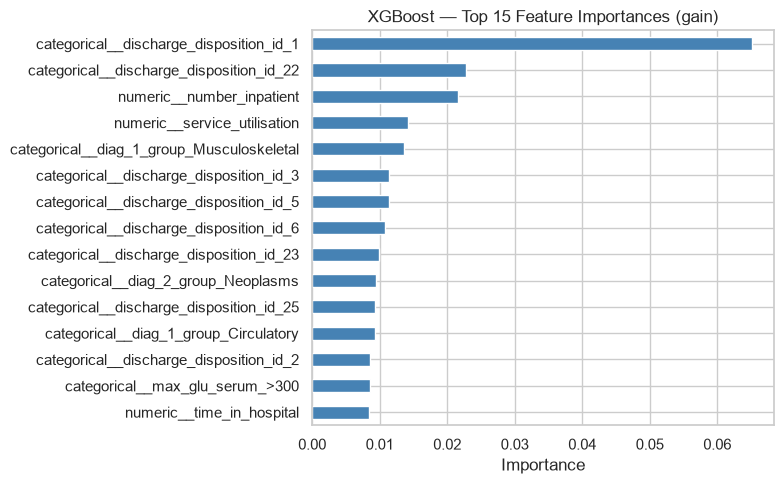

In [6]:
# 3.2.2 — Advanced model evaluated on validation
xgb_val_metrics = evaluate(xgb_pipeline, X_val, y_val)
display(pd.Series(xgb_val_metrics, name="XGBoost (validation)").round(4).to_frame())

xgb_val_pred = (xgb_pipeline.predict_proba(X_val)[:, 1] >= THRESHOLD).astype(int)
print(classification_report(y_val, xgb_val_pred, target_names=["not readmitted <30d", "readmitted <30d"], digits=3))

importances = pd.Series(
    xgb_pipeline.named_steps["model"].feature_importances_,
    index=xgb_pipeline.named_steps["preprocess"].get_feature_names_out(),
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importances.head(15).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_title("XGBoost — Top 15 Feature Importances (gain)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## Task 3.3 — Model Evaluation [5 Marks]

### 3.3.1 — Imbalance-aware metrics + model selection [3] — ROC-AUC, PR-AUC, recall, precision, and F1; select the final model using ROC-AUC.

Both models are compared on validation with ROC-AUC, PR-AUC, recall, precision and F1. A majority-class reference ("always predict not readmitted") is included to show why accuracy is not used. The final model is the one with the highest **validation ROC-AUC**, checked against the ≥ 0.70 target from Task 1.1.2. The selected model is then scored **once** on the held-out test split to confirm it generalises.

In [7]:
# 3.3.1 — Imbalance-aware metrics + model selection (ROC-AUC, PR-AUC, recall, precision, F1; select by ROC-AUC)
majority_reference = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

models = {
    "Logistic Regression": baseline_pipeline,
    "XGBoost": xgb_pipeline,
}
validation_metrics = {
    "Logistic Regression": baseline_val_metrics,
    "XGBoost": xgb_val_metrics,
    "Majority-class reference": evaluate(majority_reference, X_val, y_val),
}

comparison = pd.DataFrame(validation_metrics).T[["roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy"]]
comparison.index.name = "model (validation)"
display(comparison.round(4).style.highlight_max(subset=["roc_auc", "pr_auc", "recall", "f1"], color="lightgreen"))

ROC_AUC_TARGET = 0.70
best_model_name = comparison.loc[list(models), "roc_auc"].idxmax()
best_pipeline = models[best_model_name]
best_val_roc_auc = comparison.loc[best_model_name, "roc_auc"]
print(f"Selected model (highest validation ROC-AUC): {best_model_name} — ROC-AUC {best_val_roc_auc:.4f}")
print(f"Meets the ROC-AUC >= {ROC_AUC_TARGET} target: {best_val_roc_auc >= ROC_AUC_TARGET}")

# Final, one-time check of the selected model on the untouched test split.
best_test_metrics = evaluate(best_pipeline, X_test, y_test)
display(
    pd.DataFrame({"validation": comparison.loc[best_model_name], "test": pd.Series(best_test_metrics)})
    .round(4)
    .rename_axis(f"{best_model_name} metric")
)

,roc_auc,pr_auc,recall,precision,f1,accuracy
model (validation),,,,,,
Logistic Regression,0.652500,0.172300,0.530800,0.138700,0.219900,0.662100
XGBoost,0.665000,0.180200,0.553100,0.146000,0.231000,0.669600
Majority-class reference,0.500000,0.089700,0.000000,0.000000,0.000000,0.910300


Selected model (highest validation ROC-AUC): XGBoost — ROC-AUC 0.6650
Meets the ROC-AUC >= 0.7 target: False


,validation,test
XGBoost metric,,
roc_auc,0.6650,0.6556
pr_auc,0.1802,0.1799
recall,0.5531,0.5292
precision,0.1460,0.1422
f1,0.2310,0.2242
accuracy,0.6696,0.6716


### 3.3.2 — Plots + interpretation (why accuracy misleads) [2] — Confusion + ROC plots with interpretation.

The confusion matrices (0.50 threshold) show the actual error counts for each model on validation. The ROC and precision–recall curves compare ranking quality across all thresholds. The dotted line marks a no-skill model, and in the PR plot it sits at the ~9% positive rate.

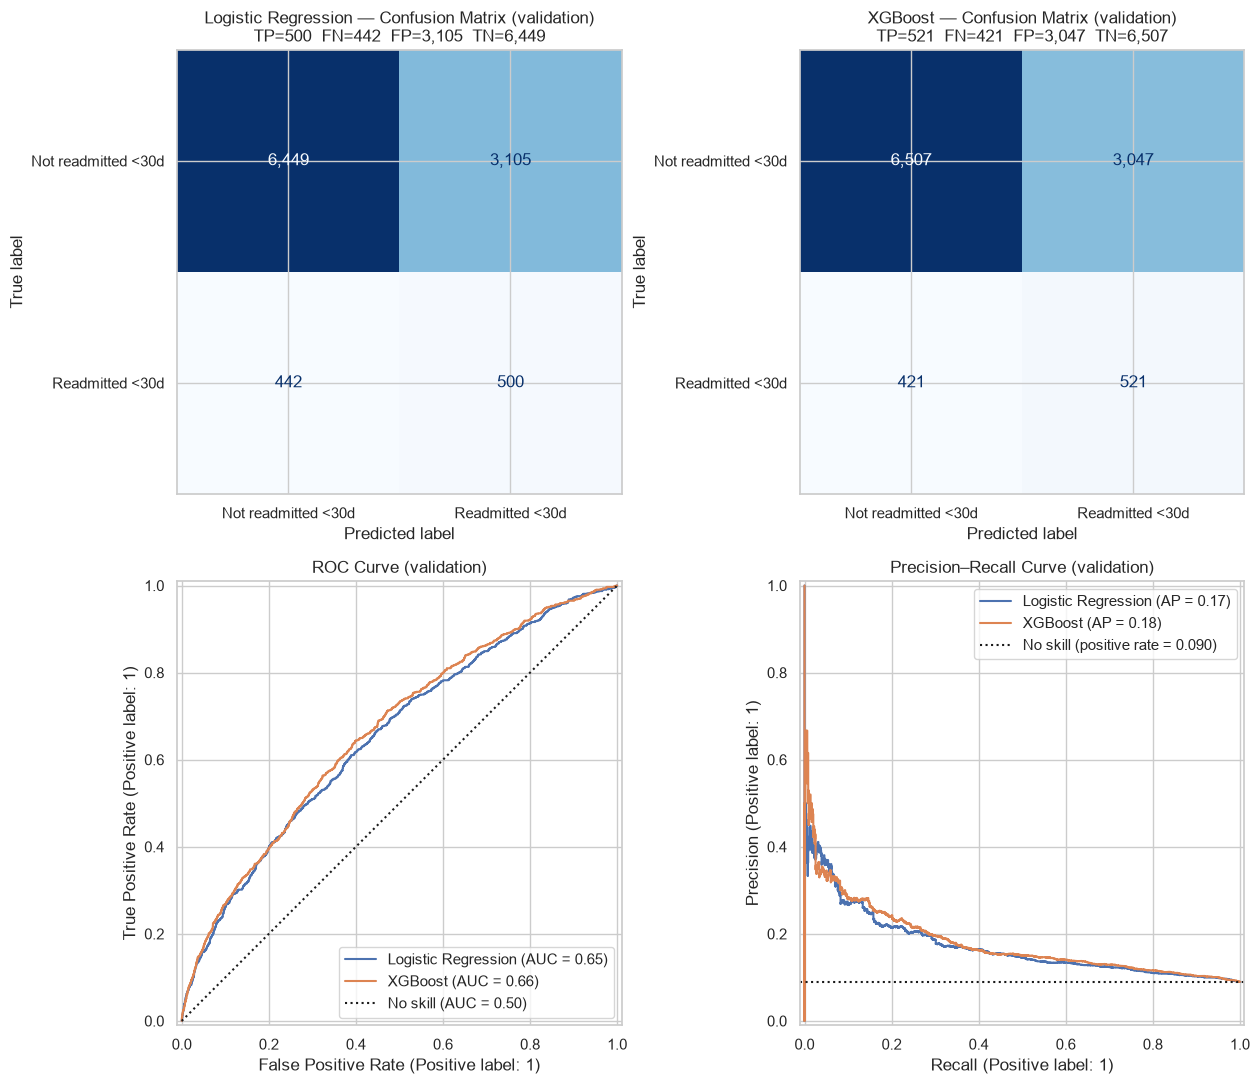

Majority-class reference: accuracy 91.03%, recall 0.00%, ROC-AUC 0.50 — it never flags a single readmission.
Logistic Regression: accuracy 66.21%, recall 53.08%, precision 13.87%, ROC-AUC 0.6525
XGBoost: accuracy 66.96%, recall 55.31%, precision 14.60%, ROC-AUC 0.6650


In [8]:
# 3.3.2 — Plots + interpretation (why accuracy misleads): confusion + ROC plots
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

for ax, (name, model) in zip(axes[0], models.items()):
    predictions = (model.predict_proba(X_val)[:, 1] >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        display_labels=["Not readmitted <30d", "Readmitted <30d"],
        cmap="Blues",
        values_format=",",
        colorbar=False,
        ax=ax,
    )
    tn, fp, fn, tp = confusion_matrix(y_val, predictions).ravel()
    ax.set_title(f"{name} — Confusion Matrix (validation)\nTP={tp:,}  FN={fn:,}  FP={fp:,}  TN={tn:,}")

for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_val, y_val, name=name, ax=axes[1, 0])
    PrecisionRecallDisplay.from_estimator(model, X_val, y_val, name=name, ax=axes[1, 1])
axes[1, 0].plot([0, 1], [0, 1], "k:", label="No skill (AUC = 0.50)")
axes[1, 0].set_title("ROC Curve (validation)")
axes[1, 0].legend(loc="lower right")
axes[1, 1].axhline(y_val.mean(), color="k", linestyle=":", label=f"No skill (positive rate = {y_val.mean():.3f})")
axes[1, 1].set_title("Precision–Recall Curve (validation)")
axes[1, 1].legend(loc="upper right")

plt.tight_layout()
plt.show()

majority = validation_metrics["Majority-class reference"]
print(f"Majority-class reference: accuracy {majority['accuracy']:.2%}, recall {majority['recall']:.2%}, "
      f"ROC-AUC {majority['roc_auc']:.2f} — it never flags a single readmission.")
for name in models:
    m = validation_metrics[name]
    print(f"{name}: accuracy {m['accuracy']:.2%}, recall {m['recall']:.2%}, precision {m['precision']:.2%}, "
          f"ROC-AUC {m['roc_auc']:.4f}")

#### Interpretation

**Why accuracy misleads.** Only 8.97% of validation patients are readmitted within 30 days. A model that always predicts "not readmitted" scores **91.03% accuracy**, the highest in the table, but has **0% recall** and ROC-AUC 0.50: it misses all 942 readmissions. Both real models score lower on accuracy (66?67%) because they deliberately flag more patients in order to catch readmissions. Accuracy rewards the useless model, so it is reported but never used for selection.

**Confusion matrices (validation, threshold 0.50).**
- **XGBoost:** catches **521 of 942** readmissions (recall 55.3%) and misses 421 (false negatives). It raises 3,047 false alarms, so about 1 in 7 flagged patients is a true readmission (precision 14.6%).
- **Logistic Regression:** catches 500 (recall 53.1%), misses 442, and raises 3,105 false alarms (precision 13.9%).
- XGBoost is better on every error type: 21 more readmissions caught and 58 fewer false alarms.

**ROC and precision?recall curves.** XGBoost's ROC curve lies slightly above Logistic Regression's across most thresholds (ROC-AUC **0.665 vs 0.653**), and its PR-AUC is higher (0.180 vs 0.172). Both PR curves sit about 2? above the 0.09 no-skill line. The models rank risk meaningfully better than chance, but the classes overlap substantially.

**Selection and caveats.**
- **XGBoost** is selected on validation ROC-AUC. Its test ROC-AUC (0.656) is close to validation, so the result is not over-fitted to the validation split.
- Neither model reaches the ? 0.70 project target from 1.1.2. With one encounter per patient and only discharge-time features, roughly 0.65?0.68 is typical for this dataset. The shortfall is reported rather than hidden.
- At the 0.50 threshold the model works as a **screening aid**: it flags ~34% of patients to catch ~55% of readmissions. The threshold can be moved along the ROC/PR curves (decided on validation) to trade recall against care-team workload.

## Task 3.4 — MLflow Experiment Tracking [7 Marks]

### 3.4.1 — Both runs logged with params + metrics + model [4]

Each model gets its own MLflow run in the `hospital-readmission-30d` experiment. Each run logs:

- **Parameters:** all model hyperparameters, the imbalance strategy, the decision threshold, the random seed, split sizes and the number of input/encoded features.
- **Metrics:** validation ROC-AUC, PR-AUC, recall, precision, F1 and accuracy, plus training time.
- **Model:** the complete preprocessing + classifier `Pipeline`, with an input signature and an input example, so the API can load one object and get the same preprocessing. It is saved in MLflow's `skops` format, with the required types explicitly trusted.
- **Run metadata:** tags (model family, stage, dataset, selection metric) and the confusion-matrix figure as an artifact.

Every execution creates new runs; earlier runs are never overwritten.

In [9]:
# 3.4.1 — Both runs logged with params + metrics + model
COMMON_PARAMS = {
    "random_state": RANDOM_STATE,
    "decision_threshold": THRESHOLD,
    "split_ratio": "70/15/15 stratified",
    "n_train": len(X_train),
    "n_validation": len(X_val),
    "n_test": len(X_test),
    "n_input_features": X_train.shape[1],
    "n_encoded_features": n_features_out,
    "train_positive_rate": round(float(y_train.mean()), 4),
}

run_specs = {
    "Logistic Regression": {
        "run_name": "baseline_logistic_regression",
        "pipeline": baseline_pipeline,
        "model_params": LR_PARAMS,
        "imbalance_strategy": "class_weight=balanced",
        "train_seconds": baseline_train_seconds,
        "model_family": "logistic_regression",
    },
    "XGBoost": {
        "run_name": "advanced_xgboost",
        "pipeline": xgb_pipeline,
        "model_params": XGB_PARAMS,
        "imbalance_strategy": "scale_pos_weight=negatives/positives (train)",
        "train_seconds": xgb_train_seconds,
        "model_family": "xgboost",
    },
}

signature_input = X_train.head(200)
run_ids, model_uris = {}, {}
for name, spec in run_specs.items():
    pipeline = spec["pipeline"]
    with mlflow.start_run(run_name=spec["run_name"]) as run:
        mlflow.set_tags(
            {
                "model_family": spec["model_family"],
                "stage": "stage3_model_development",
                "dataset": "diabetes_130_us_hospitals",
                "selection_metric": "val_roc_auc",
            }
        )
        mlflow.log_params({f"model__{k}": v for k, v in spec["model_params"].items()})
        mlflow.log_params({**COMMON_PARAMS, "imbalance_strategy": spec["imbalance_strategy"]})
        mlflow.log_metrics({f"val_{k}": v for k, v in validation_metrics[name].items()})
        mlflow.log_metric("train_seconds", spec["train_seconds"])

        val_pred = (pipeline.predict_proba(X_val)[:, 1] >= THRESHOLD).astype(int)
        cm_display = ConfusionMatrixDisplay.from_predictions(y_val, val_pred, cmap="Blues", values_format=",")
        cm_display.ax_.set_title(f"{name} — validation confusion matrix")
        mlflow.log_figure(cm_display.figure_, "plots/validation_confusion_matrix.png")
        plt.close(cm_display.figure_)

        signature = infer_signature(signature_input, pipeline.predict_proba(signature_input)[:, 1])
        trusted_types = sio.get_untrusted_types(data=sio.dumps(pipeline))
        model_info = mlflow.sklearn.log_model(
            pipeline,
            name="model",
            signature=signature,
            input_example=X_train.head(3),
            skops_trusted_types=trusted_types,
        )
        run_ids[name] = run.info.run_id
        model_uris[name] = model_info.model_uri
    print(f"Logged {name}: run_id={run.info.run_id}  model_uri={model_info.model_uri}")

Logged Logistic Regression: run_id=07f45fb1663245bfb6b60ab7d5605ca9  model_uri=models:/m-b9f09d88913c4d399aeeed9d4f07979e


Logged XGBoost: run_id=c10bb43f1120428d8f1665253cd6d577  model_uri=models:/m-aefb7312976b4642a4b1e393d0f35824


### 3.4.2 — Runs compared (search_runs table) [3]

`mlflow.search_runs` reads the two runs back from the tracking store, which confirms that the parameters and metrics were saved. It returns them as one comparison table, sorted by the selection metric (validation ROC-AUC).

In [10]:
# 3.4.2 — Runs compared (search_runs table)
run_id_filter = ", ".join(f"'{run_id}'" for run_id in run_ids.values())
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME],
    filter_string=f"attributes.run_id IN ({run_id_filter})",
    order_by=["metrics.val_roc_auc DESC"],
)

comparison_columns = {
    "tags.mlflow.runName": "run_name",
    "run_id": "run_id",
    "params.imbalance_strategy": "imbalance_strategy",
    "metrics.val_roc_auc": "val_roc_auc",
    "metrics.val_pr_auc": "val_pr_auc",
    "metrics.val_recall": "val_recall",
    "metrics.val_precision": "val_precision",
    "metrics.val_f1": "val_f1",
    "metrics.val_accuracy": "val_accuracy",
    "metrics.train_seconds": "train_seconds",
    "start_time": "start_time",
}
runs_table = runs[list(comparison_columns)].rename(columns=comparison_columns).set_index("run_name")
display(runs_table.round(4))

best_run_name = runs_table.index[0]
best_run_id = runs_table.loc[best_run_name, "run_id"]
assert best_run_id == run_ids[best_model_name], "MLflow ranking disagrees with the in-notebook selection"
print(f"Best run by val_roc_auc: {best_run_name} ({best_run_id}) — matches the 3.3.1 selection: {best_model_name}")
print(f"All runs in experiment '{EXPERIMENT_NAME}': {len(mlflow.search_runs(experiment_names=[EXPERIMENT_NAME]))}")

,run_id,imbalance_strategy,val_roc_auc,val_pr_auc,val_recall,val_precision,val_f1,val_accuracy,train_seconds,start_time
run_name,,,,,,,,,,
advanced_xgboost,c10bb43f1120428d8f1665253cd6d577,scale_pos_weight=negatives/positives (train),0.6650,0.1802,0.5531,0.1460,0.2310,0.6696,3.9395,2026-11-08 07:22:04.066+00:00
baseline_logistic_regression,07f45fb1663245bfb6b60ab7d5605ca9,class_weight=balanced,0.6525,0.1723,0.5308,0.1387,0.2199,0.6621,2.2421,2026-11-08 07:21:54.523+00:00


Best run by val_roc_auc: advanced_xgboost (c10bb43f1120428d8f1665253cd6d577) — matches the 3.3.1 selection: XGBoost
All runs in experiment 'hospital-readmission-30d': 2


## Task 3.5 — Model Registry & Versioning [5 Marks]

### 3.5.1 — Best model registered in the MLflow Model Registry [2]

Only the selected model (highest validation ROC-AUC) is registered under `hospital-readmission-30d-classifier`. Each registration creates a new version. The version is tagged with its model family and validation metrics, and its description records why it was selected.

In [11]:
# 3.5.1 — Best model registered in the MLflow Model Registry
client = MlflowClient()

# MLflow 3 stores the logged model under its own URI (models:/m-...), linked to the source run.
registered_version = mlflow.register_model(model_uris[best_model_name], REGISTERED_MODEL_NAME)
client.update_registered_model(
    REGISTERED_MODEL_NAME,
    description="Predicts 30-day readmission risk for diabetic inpatients (Diabetes 130-US Hospitals). "
    "Full preprocessing + classifier sklearn Pipeline; input = one encounter's features.",
)
client.update_model_version(
    REGISTERED_MODEL_NAME,
    registered_version.version,
    description=f"{best_model_name} selected by validation ROC-AUC = {best_val_roc_auc:.4f} "
    f"(Stage 3, run {best_run_id}).",
)
version_tags = {
    "model_family": run_specs[best_model_name]["model_family"],
    "val_roc_auc": f"{best_val_roc_auc:.4f}",
    "val_recall": f"{validation_metrics[best_model_name]['recall']:.4f}",
    "test_roc_auc": f"{best_test_metrics['roc_auc']:.4f}",
    "selection_metric": "val_roc_auc",
}
for key, value in version_tags.items():
    client.set_model_version_tag(REGISTERED_MODEL_NAME, registered_version.version, key, value)

print(f"Registered '{REGISTERED_MODEL_NAME}' version {registered_version.version} from run {best_run_id} ({best_model_name})")

Registered 'hospital-readmission-30d-classifier' version 1 from run c10bb43f1120428d8f1665253cd6d577 (XGBoost)


Successfully registered model 'hospital-readmission-30d-classifier'.
Created version '1' of model 'hospital-readmission-30d-classifier'.


### 3.5.2 — Promotion to production alias + version history [3]

The new version is promoted by pointing the `production` alias at it. The API will load `models:/hospital-readmission-30d-classifier@production`, so promotion or rollback only means moving the alias, with no code change. The version history lists every registered version, with its source run, metrics and current aliases. Loading the model through the alias and comparing its predictions with the in-memory pipeline confirms the correct model is being served.

In [12]:
# 3.5.2 — Promotion to production alias + version history
client.set_registered_model_alias(REGISTERED_MODEL_NAME, PRODUCTION_ALIAS, registered_version.version)
production_version = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, PRODUCTION_ALIAS)
print(f"Alias '{PRODUCTION_ALIAS}' -> version {production_version.version}")

# search_model_versions does not populate aliases, so fetch each version individually.
versions = [
    client.get_model_version(REGISTERED_MODEL_NAME, v.version)
    for v in client.search_model_versions(f"name = '{REGISTERED_MODEL_NAME}'")
]
version_history = pd.DataFrame(
    [
        {
            "version": int(v.version),
            "aliases": ", ".join(v.aliases) or "-",
            "model_family": v.tags.get("model_family"),
            "val_roc_auc": v.tags.get("val_roc_auc"),
            "val_recall": v.tags.get("val_recall"),
            "status": v.status,
            "run_id": v.run_id,
            "created": pd.to_datetime(v.creation_timestamp, unit="ms").strftime("%Y-%m-%d %H:%M:%S"),
        }
        for v in versions
    ]
).sort_values("version", ascending=False).set_index("version")
print("Version history:")
display(version_history)

# Verify the alias serves the selected pipeline.
production_model = mlflow.sklearn.load_model(f"models:/{REGISTERED_MODEL_NAME}@{PRODUCTION_ALIAS}")
alias_scores = production_model.predict_proba(X_val)[:, 1]
assert np.allclose(alias_scores, best_pipeline.predict_proba(X_val)[:, 1])
print(f"models:/{REGISTERED_MODEL_NAME}@{PRODUCTION_ALIAS} reproduces the selected pipeline's predictions "
      f"(validation ROC-AUC {roc_auc_score(y_val, alias_scores):.4f}).")

Alias 'production' -> version 1
Version history:


,aliases,model_family,val_roc_auc,val_recall,status,run_id,created
version,,,,,,,
1,production,xgboost,0.6650,0.5531,READY,c10bb43f1120428d8f1665253cd6d577,2026-11-08 07:22:12


models:/hospital-readmission-30d-classifier@production reproduces the selected pipeline's predictions (validation ROC-AUC 0.6650).
